<a href="https://colab.research.google.com/github/RachmadAprisandhy/PBL_Kelompok3/blob/Zacky/Klasifikasi_Grading_Pisang_Machine_Learning_Gabungan_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1. Menghubungkan Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Langkah 2. Menentukan lokasi dataset

In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Dataset PBL/Banana Images/Gabungan Dataset"

train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

print("Isi folder train:", os.listdir(train_path))
print("Isi folder test:", os.listdir(test_path))

Isi folder train: ['Grade D', 'Grade B', 'Grade C', 'Grade A']
Isi folder test: ['Grade C', 'Grade D', 'Grade B', 'Grade A']


Langkah 3. Menghitung jumlah gambar

In [ ]:
grades = ["Grade A", "Grade B", "Grade C", "Grade D"]

for grade in grades:
    jumlah_train = len(os.listdir(os.path.join(train_path, grade)))
    jumlah_test = len(os.listdir(os.path.join(test_path, grade)))

    print(f"{grade}")
    print(f"  Training : {jumlah_train}")
    print(f"  Testing  : {jumlah_test}")

Grade A
  Training : 2001
  Testing  : 500
Grade B
  Training : 2001
  Testing  : 500
Grade C
  Training : 2000
  Testing  : 500
Grade D
  Training : 2000
  Testing  : 500


Langkah 4. Menampilkan contoh gambar

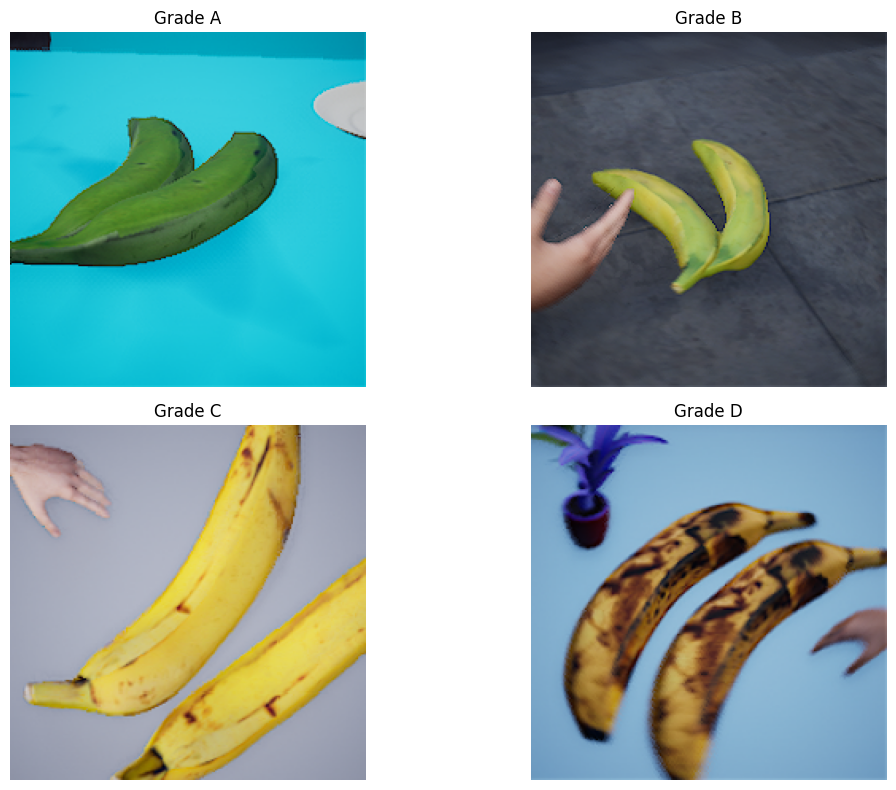

In [ ]:
import cv2
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i, grade in enumerate(grades):
    folder = os.path.join(train_path, grade)
    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 2, i+1)
    plt.imshow(image)
    plt.title(grade)
    plt.axis("off")

plt.tight_layout()
plt.show()

Langkah 5. Preprocessing citra

5.1 Import library

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

5.2 Mengambil satu gambar dari dataset

In [ ]:
grade = "Grade A"

folder = os.path.join(train_path, grade)

image_name = os.listdir(folder)[0]

image_path = os.path.join(folder, image_name)

image = cv2.imread(image_path)

print("Nama gambar:", image_name)
print("Ukuran gambar asli:", image.shape)

Nama gambar: TipoA1_2_Celeste_P_V0002.png
Ukuran gambar asli: (224, 224, 3)


5.3 Mengubah ukuran gambar (Resize)

In [ ]:
# Mengubah ukuran gambar menjadi 224 x 224
resized = cv2.resize(image, (224, 224))

print("Ukuran setelah resize:", resized.shape)

Ukuran setelah resize: (224, 224, 3)


5.4 Konversi BGR ke RGB

In [ ]:
rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)

5.5 Konversi RGB ke HSV

In [ ]:
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

5.6 Mengubah gambar menjadi Grayscale

In [ ]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

5.7 Menampilkan hasil preprocessing

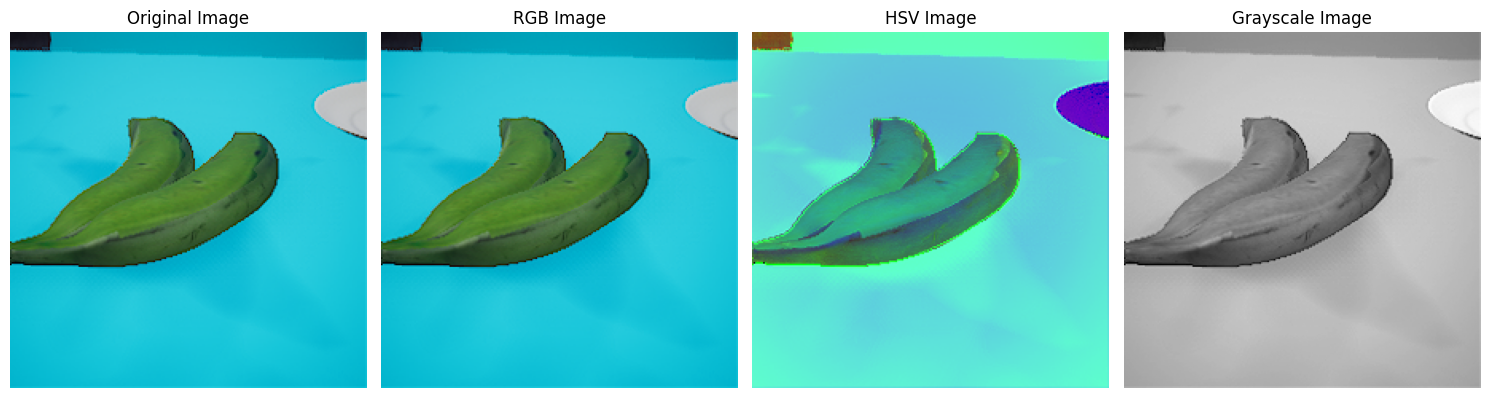

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(rgb)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(hsv)
plt.title("HSV Image")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Langkah 6. Image Segmentation

6.1 Memahami Tujuan Segmentasi

Segmentasi citra (Image Segmentation) merupakan proses memisahkan objek utama dari latar belakang (background) pada sebuah gambar. Dalam penelitian ini, segmentasi dilakukan untuk memisahkan objek pisang dari latar belakang sehingga proses pengolahan citra dapat lebih berfokus pada karakteristik pisang. Hasil segmentasi akan membagi citra menjadi dua bagian, yaitu foreground yang merupakan objek pisang dan background yang merupakan area di luar objek pisang. Dengan demikian, proses ekstraksi fitur warna, bentuk, dan tekstur dapat dilakukan secara lebih terarah untuk membantu klasifikasi kualitas pisang berdasarkan Grade A, B, C, dan D.

6.2 Mengambil channel Saturation dari HSV

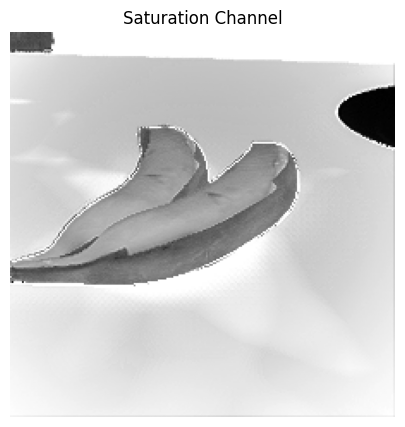

In [ ]:
# Mengambil channel Saturation
saturation = hsv[:, :, 1]

plt.figure(figsize=(6, 5))
plt.imshow(saturation, cmap="gray")
plt.title("Saturation Channel")
plt.axis("off")
plt.show()

6.3 Membuat Binary Mask menggunakan Otsu Thresholding

Nilai threshold: 169.0


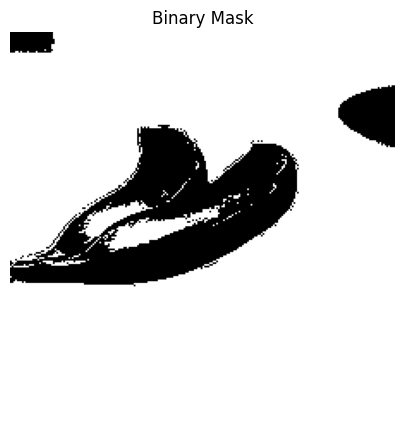

In [ ]:
# Otsu Thresholding
threshold_value, mask = cv2.threshold(
    saturation,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Nilai threshold:", threshold_value)

plt.figure(figsize=(6, 5))
plt.imshow(mask, cmap="gray")
plt.title("Binary Mask")
plt.axis("off")
plt.show()

6.4 Memperbaiki hasil segmentasi (Morphological Operations)

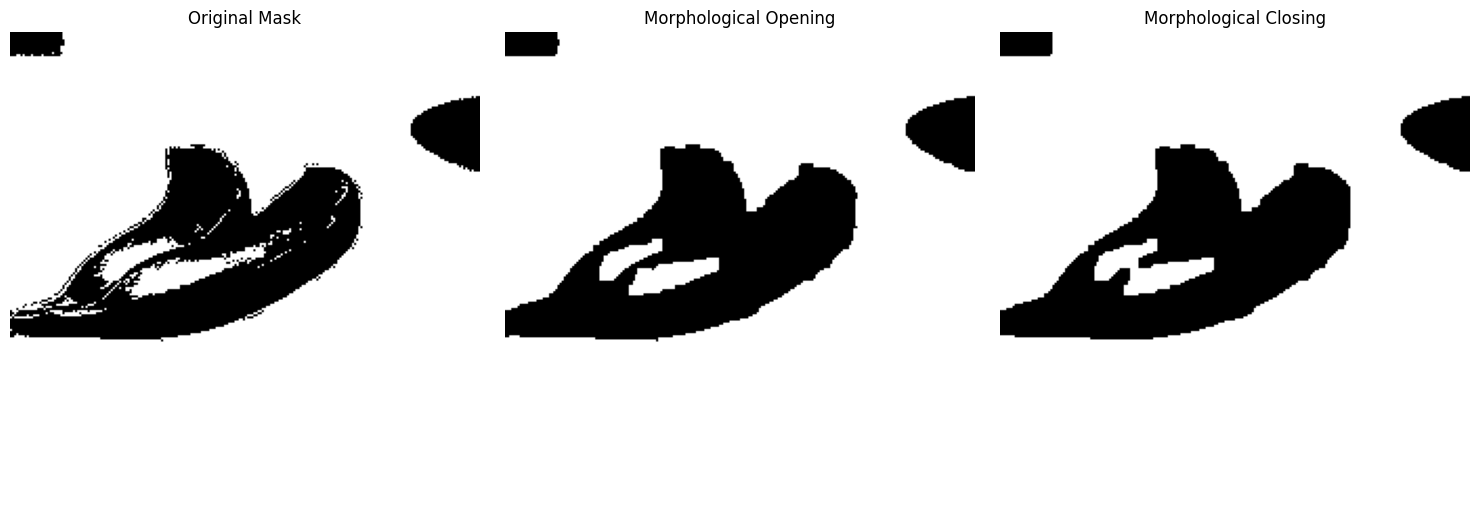

In [ ]:
# Membuat kernel
kernel = np.ones((5, 5), np.uint8)

# Menghilangkan noise kecil
opening = cv2.morphologyEx(
    mask,
    cv2.MORPH_OPEN,
    kernel
)

# Menutup lubang kecil
closing = cv2.morphologyEx(
    opening,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original Mask")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opening, cmap="gray")
plt.title("Morphological Opening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(closing, cmap="gray")
plt.title("Morphological Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

6.5 Mengambil kontur objek pisang

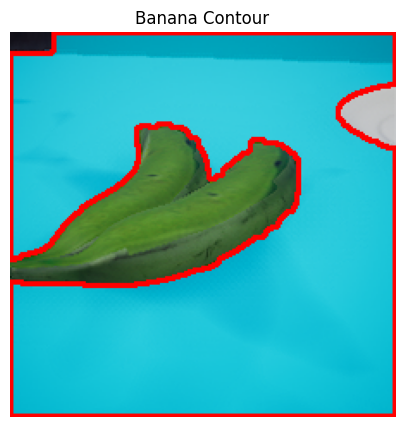

In [ ]:
contours, hierarchy = cv2.findContours(
    closing,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if len(contours) > 0:

    largest_contour = max(contours, key=cv2.contourArea)

    contour_image = rgb.copy()

    cv2.drawContours(
        contour_image,
        [largest_contour],
        -1,
        (255, 0, 0),
        2
    )

    plt.figure(figsize=(7, 5))
    plt.imshow(contour_image)
    plt.title("Banana Contour")
    plt.axis("off")
    plt.show()

else:
    print("Objek tidak ditemukan!")

6.6 Menghasilkan gambar pisang tanpa background

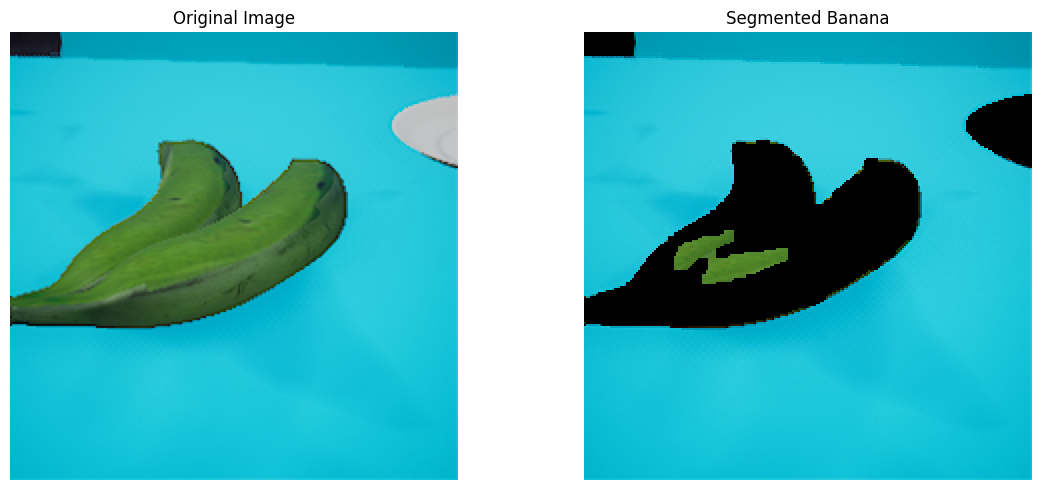

In [ ]:
# Membuat gambar hasil segmentasi
segmented = cv2.bitwise_and(
    rgb,
    rgb,
    mask=closing
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented)
plt.title("Segmented Banana")
plt.axis("off")

plt.tight_layout()
plt.show()

Langkah 7. Ekstraksi Fitur Citra (Feature Extraction)

7.1 Memahami tujuan ekstraksi fitur

Ekstraksi fitur (Feature Extraction) merupakan proses mengambil informasi atau karakteristik penting dari sebuah citra untuk diubah menjadi data numerik yang dapat diproses oleh algoritma Machine Learning. Dalam penelitian ini, ekstraksi fitur dilakukan untuk memperoleh karakteristik visual dari buah pisang berdasarkan tiga aspek utama, yaitu warna (Color Features), bentuk (Shape Features), dan tekstur (Texture Features). Fitur warna digunakan untuk menganalisis karakteristik warna kulit pisang, fitur bentuk digunakan untuk mengetahui ukuran dan bentuk fisik objek pisang, sedangkan fitur tekstur digunakan untuk menganalisis pola permukaan kulit pisang, seperti bercak dan tingkat kekasaran. Hasil ekstraksi dari ketiga aspek tersebut nantinya akan digunakan sebagai dasar dalam proses klasifikasi kualitas pisang ke dalam Grade A, B, C, dan D menggunakan algoritma Classical Machine Learning.

7.2 Color Feature Extraction (Ekstraksi Fitur Warna)

In [ ]:
# Mengambil piksel objek pisang berdasarkan mask segmentasi
mask_binary = closing > 0

# Ekstraksi fitur warna RGB
color_rgb = rgb[mask_binary]

mean_r = np.mean(color_rgb[:, 0])
mean_g = np.mean(color_rgb[:, 1])
mean_b = np.mean(color_rgb[:, 2])

std_r = np.std(color_rgb[:, 0])
std_g = np.std(color_rgb[:, 1])
std_b = np.std(color_rgb[:, 2])

# Ekstraksi fitur warna HSV
color_hsv = hsv[mask_binary]

mean_h = np.mean(color_hsv[:, 0])
mean_s = np.mean(color_hsv[:, 1])
mean_v = np.mean(color_hsv[:, 2])

std_h = np.std(color_hsv[:, 0])
std_s = np.std(color_hsv[:, 1])
std_v = np.std(color_hsv[:, 2])

print("=== COLOR FEATURES ===")
print("Mean RGB:", mean_r, mean_g, mean_b)
print("Mean HSV:", mean_h, mean_s, mean_v)
print("Std RGB:", std_r, std_g, std_b)
print("Std HSV:", std_h, std_s, std_v)

=== COLOR FEATURES ===
Mean RGB: 29.024337466569413 191.19372720641869 209.47004619499148
Mean HSV: 91.96460004862631 221.58144906394358 211.34779965961584
Std RGB: 17.845563975825137 19.390646945178784 29.99019922447598
Std HSV: 8.233258263921272 20.02655157400816 20.048282181428664


7.3 Shape Feature Extraction (Ekstraksi Fitur Bentuk)

In [ ]:
# Mencari kontur objek
contours, _ = cv2.findContours(
    closing,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if len(contours) > 0:

    largest_contour = max(contours, key=cv2.contourArea)

    # Menghitung luas objek
    area = cv2.contourArea(largest_contour)

    # Menghitung keliling objek
    perimeter = cv2.arcLength(
        largest_contour,
        True
    )

    # Menghitung bounding box
    x, y, w, h = cv2.boundingRect(largest_contour)

    # Menghitung rasio panjang dan lebar
    aspect_ratio = w / h if h != 0 else 0

    # Menghitung circularity
    circularity = (
        4 * np.pi * area / (perimeter ** 2)
        if perimeter != 0 else 0
    )

    print("=== SHAPE FEATURES ===")
    print("Area:", area)
    print("Perimeter:", perimeter)
    print("Width:", w)
    print("Height:", h)
    print("Aspect Ratio:", aspect_ratio)
    print("Circularity:", circularity)

else:
    print("Kontur objek tidak ditemukan!")

=== SHAPE FEATURES ===
Area: 39726.5
Perimeter: 1407.3452327251434
Width: 224
Height: 224
Aspect Ratio: 1.0
Circularity: 0.2520512617027387


7.4 Texture Feature Extraction (Ekstraksi Fitur Tekstur)

In [ ]:
from skimage.feature import graycomatrix, graycoprops

# Membuat bounding box dari objek pisang
x, y, w, h = cv2.boundingRect(largest_contour)

# Mengambil bagian gambar yang mengandung pisang
gray_crop = gray[y:y+h, x:x+w]

# Mengambil mask pada area yang sama
mask_crop = closing[y:y+h, x:x+w] > 0

# Mengisi background dengan rata-rata grayscale objek
gray_crop = gray_crop.copy()

if np.any(mask_crop):
    fill_value = int(np.mean(gray_crop[mask_crop]))
    gray_crop[~mask_crop] = fill_value

# Mengurangi level grayscale menjadi 8 tingkat
gray_quantized = (gray_crop // 32).astype(np.uint8)

# Membuat GLCM
glcm = graycomatrix(
    gray_quantized,
    distances=[1],
    angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
    levels=8,
    symmetric=True,
    normed=True
)

# Menghitung fitur tekstur
contrast = graycoprops(glcm, 'contrast').mean()
homogeneity = graycoprops(glcm, 'homogeneity').mean()
energy = graycoprops(glcm, 'energy').mean()
correlation = graycoprops(glcm, 'correlation').mean()

print("=== TEXTURE FEATURES ===")
print("Contrast:", contrast)
print("Homogeneity:", homogeneity)
print("Energy:", energy)
print("Correlation:", correlation)

=== TEXTURE FEATURES ===
Contrast: 0.1068137295211475
Homogeneity: 0.9777454903772533
Energy: 0.8134424437185246
Correlation: 0.7739730084003826


7.5 Menggabungkan hasil ekstraksi fitur sementara

In [ ]:
import pandas as pd

# Menggabungkan seluruh fitur
features = {
    "Mean_R": mean_r,
    "Mean_G": mean_g,
    "Mean_B": mean_b,
    "Mean_H": mean_h,
    "Mean_S": mean_s,
    "Mean_V": mean_v,

    "Std_R": std_r,
    "Std_G": std_g,
    "Std_B": std_b,
    "Std_H": std_h,
    "Std_S": std_s,
    "Std_V": std_v,

    "Area": area,
    "Perimeter": perimeter,
    "Width": w,
    "Height": h,
    "Aspect_Ratio": aspect_ratio,
    "Circularity": circularity,

    "Contrast": contrast,
    "Homogeneity": homogeneity,
    "Energy": energy,
    "Correlation": correlation
}

# Mengubah menjadi DataFrame
df_features = pd.DataFrame([features])

display(df_features)

,Mean_R,Mean_G,Mean_B,Mean_H,Mean_S,Mean_V,Std_R,Std_G,Std_B,Std_H,...,Area,Perimeter,Width,Height,Aspect_Ratio,Circularity,Contrast,Homogeneity,Energy,Correlation
0,29.024337,191.193727,209.470046,91.9646,221.581449,211.3478,17.845564,19.390647,29.990199,8.233258,...,39726.5,1407.345233,224,224,1.0,0.252051,0.106814,0.977745,0.813442,0.773973


Langkah 8. Ekstraksi Fitur Seluruh Dataset

8.1 Memahami tujuan ekstraksi fitur seluruh dataset

Pada tahap ini, proses ekstraksi fitur dilakukan terhadap seluruh gambar pisang yang terdapat pada dataset training dan testing. Setiap gambar akan melalui proses preprocessing, segmentasi, serta ekstraksi fitur warna, bentuk, dan tekstur. Hasil ekstraksi tersebut kemudian disimpan dalam bentuk tabel yang berisi nilai numerik dan label kelas masing-masing gambar. Dengan demikian, seluruh karakteristik citra pisang dapat direpresentasikan sebagai data terstruktur yang siap digunakan dalam proses klasifikasi menggunakan algoritma Machine Learning.

8.2 Membuat fungsi ekstraksi fitur

In [ ]:
from skimage.feature import graycomatrix, graycoprops
import cv2
import numpy as np

def extract_features(image_path):

    image = cv2.imread(image_path)

    if image is None:
        return None

    # 1. Preprocessing
    image = cv2.resize(image, (224, 224))

    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    # 2. Segmentasi
    saturation = hsv[:, :, 1]

    _, mask = cv2.threshold(
        saturation, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Pilih foreground berdasarkan mask.
    # Jika bagian tengah mask hitam, balik mask.
    if mask[112, 112] == 0:
        mask = cv2.bitwise_not(mask)

    kernel = np.ones((5, 5), np.uint8)

    opening = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    closing = cv2.morphologyEx(
        opening, cv2.MORPH_CLOSE, kernel
    )

    mask_binary = closing > 0

    if np.sum(mask_binary) < 10:
        return None

    # 3. Color Features
    color_rgb = rgb[mask_binary]
    color_hsv = hsv[mask_binary]

    features = {}

    for i, channel in enumerate(["R", "G", "B"]):
        features[f"Mean_{channel}"] = np.mean(color_rgb[:, i])
        features[f"Std_{channel}"] = np.std(color_rgb[:, i])

    for i, channel in enumerate(["H", "S", "V"]):
        features[f"Mean_{channel}"] = np.mean(color_hsv[:, i])
        features[f"Std_{channel}"] = np.std(color_hsv[:, i])

    # 4. Shape Features
    contours, _ = cv2.findContours(
        closing,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        return None

    largest = max(contours, key=cv2.contourArea)

    area = cv2.contourArea(largest)
    perimeter = cv2.arcLength(largest, True)

    x, y, w, h = cv2.boundingRect(largest)

    features["Area"] = area
    features["Perimeter"] = perimeter
    features["Width"] = w
    features["Height"] = h
    features["Aspect_Ratio"] = w / h if h > 0 else 0

    features["Circularity"] = (
        4 * np.pi * area / (perimeter ** 2)
        if perimeter > 0 else 0
    )

    # 5. Texture Features
    gray_crop = gray[y:y+h, x:x+w]
    mask_crop = closing[y:y+h, x:x+w] > 0

    if np.any(mask_crop):
        fill_value = int(np.mean(gray_crop[mask_crop]))
        gray_crop = gray_crop.copy()
        gray_crop[~mask_crop] = fill_value

    gray_quantized = (gray_crop // 32).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=[1],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=8,
        symmetric=True,
        normed=True
    )

    for prop in ["contrast", "homogeneity", "energy", "correlation"]:
        features[prop.capitalize()] = graycoprops(
            glcm, prop
        ).mean()

    return features

8.3 Melakukan ekstraksi seluruh gambar Training

In [ ]:

import os
import pandas as pd

grades = ["Grade A", "Grade B", "Grade C", "Grade D"]

train_data = []

for grade in grades:

    folder = os.path.join(train_path, grade)

    for image_name in os.listdir(folder):

        image_path = os.path.join(folder, image_name)

        features = extract_features(image_path)

        if features is not None:

            features["Grade"] = grade
            features["Image"] = image_name

            train_data.append(features)

df_train = pd.DataFrame(train_data)

print("Jumlah data training:", len(df_train))

display(df_train.head())


Jumlah data training: 8002


,Mean_R,Std_R,Mean_G,Std_G,Mean_B,Std_B,Mean_H,Std_H,Mean_S,Std_S,...,Width,Height,Aspect_Ratio,Circularity,Contrast,Homogeneity,Energy,Correlation,Grade,Image
0,77.634153,43.030072,113.649770,38.814455,66.984383,45.798519,61.025090,19.862672,115.700205,45.563393,...,167,91,1.835165,0.183086,0.076173,0.963075,0.719030,0.849518,Grade A,TipoA1_2_Celeste_P_V0002.png
1,72.782352,23.125094,112.578706,28.209573,47.743481,22.014919,50.330517,9.415429,148.262434,36.490359,...,133,106,1.254717,0.325888,0.177570,0.942289,0.601350,0.806934,Grade A,TipoA1_2_Asset_P_V0000.png
2,88.181604,35.677897,119.209633,21.559489,70.181530,42.121403,50.697278,29.284643,131.060412,39.749952,...,195,135,1.444444,0.198520,0.090151,0.963467,0.739140,0.858775,Grade A,TipoA1_2_Celeste_M_DI0021.png
3,70.097110,22.380396,109.585454,27.091741,42.544902,11.551562,49.009686,5.861876,154.885487,19.721720,...,150,189,0.793651,0.280440,0.045924,0.977861,0.701084,0.924587,Grade A,TipoA1_2_Concrete_F_V0017.png
4,72.772680,17.630697,114.942550,22.332502,41.749948,12.785960,48.696838,8.224157,161.317421,29.567582,...,101,95,1.063158,0.321583,0.105583,0.949564,0.677519,0.815474,Grade A,TipoA1_2_Concrete_P_DI0004.png


8.4 Melakukan ekstraksi seluruh gambar Testing

In [ ]:
test_data = []

for grade in grades:

    folder = os.path.join(test_path, grade)

    for image_name in os.listdir(folder):

        image_path = os.path.join(folder, image_name)

        features = extract_features(image_path)

        if features is not None:

            features["Grade"] = grade
            features["Image"] = image_name

            test_data.append(features)

df_test = pd.DataFrame(test_data)

print("Jumlah data testing:", len(df_test))

display(df_test.head())

Jumlah data testing: 2000


,Mean_R,Std_R,Mean_G,Std_G,Mean_B,Std_B,Mean_H,Std_H,Mean_S,Std_S,...,Width,Height,Aspect_Ratio,Circularity,Contrast,Homogeneity,Energy,Correlation,Grade,Image
0,35.847334,11.705734,54.802433,13.908994,6.941344,8.137863,42.531772,6.543012,223.914971,35.929981,...,142,98,1.448980,0.261869,0.062241,0.968901,0.869677,0.680736,Grade A,179.png
1,64.509191,33.672620,70.643359,37.261638,66.522346,37.203803,73.873941,34.475007,44.876644,30.317798,...,122,114,1.070175,0.365406,0.212463,0.908470,0.501080,0.886994,Grade A,306.png
2,129.749536,38.107854,165.176340,44.706085,53.244277,31.364091,39.366910,2.801901,178.350080,36.319848,...,106,115,0.921739,0.418705,0.251223,0.912691,0.529958,0.887774,Grade A,206 (2).png
3,58.214095,21.947413,68.471765,23.632614,5.487772,8.163239,35.818141,9.702938,236.797688,25.779635,...,146,71,2.056338,0.175169,0.097868,0.963172,0.807668,0.742356,Grade A,287 (2).png
4,46.542096,13.062283,73.306379,15.474500,8.891001,9.851237,42.849979,3.770298,225.806594,31.302836,...,113,151,0.748344,0.290955,0.062639,0.968716,0.765399,0.833065,Grade A,342.png


8.5 Melihat distribusi data setiap grade

In [ ]:
print("Distribusi Training:")
print(df_train["Grade"].value_counts())

print("\nDistribusi Testing:")
print(df_test["Grade"].value_counts())

Distribusi Training:
Grade
Grade A    2001
Grade B    2001
Grade C    2000
Grade D    2000
Name: count, dtype: int64

Distribusi Testing:
Grade
Grade A    500
Grade B    500
Grade C    500
Grade D    500
Name: count, dtype: int64


8.6 Menyimpan hasil ekstraksi fitur

In [ ]:
df_train.to_csv(
    "/content/drive/MyDrive/fitur_train_Gabungan.csv",
    index=False
)

df_test.to_csv(
    "/content/drive/MyDrive/fitur_test_Gabungan.csv",
    index=False
)

print("Dataset fitur berhasil disimpan!")

Dataset fitur berhasil disimpan!


Langkah 9. Feature Fusion

9.1 Memahami tujuan Feature Fusion

Feature Fusion merupakan proses menggabungkan beberapa jenis fitur citra, yaitu fitur warna, bentuk, dan tekstur, menjadi satu kumpulan fitur yang saling melengkapi. Dalam penelitian ini, penggabungan dilakukan agar algoritma Machine Learning dapat memanfaatkan informasi visual pisang secara lebih menyeluruh dalam membedakan Grade A, B, C, dan D.

9.2 Memisahkan fitur berdasarkan kelompoknya

In [ ]:
color_features = [
    "Mean_R", "Mean_G", "Mean_B",
    "Mean_H", "Mean_S", "Mean_V",
    "Std_R", "Std_G", "Std_B",
    "Std_H", "Std_S", "Std_V"
]

shape_features = [
    "Area", "Perimeter", "Width",
    "Height", "Aspect_Ratio", "Circularity"
]

texture_features = [
    "Contrast", "Homogeneity",
    "Energy", "Correlation"
]

fusion_features = (
    color_features +
    shape_features +
    texture_features
)

print("Jumlah fitur warna:", len(color_features))
print("Jumlah fitur bentuk:", len(shape_features))
print("Jumlah fitur tekstur:", len(texture_features))
print("Total fitur gabungan:", len(fusion_features))

Jumlah fitur warna: 12
Jumlah fitur bentuk: 6
Jumlah fitur tekstur: 4
Total fitur gabungan: 22


9.3 Menampilkan hasil Feature Fusion

In [ ]:
df_fusion = df_train[
    fusion_features + ["Grade"]
]

display(df_fusion.head())

,Mean_R,Mean_G,Mean_B,Mean_H,Mean_S,Mean_V,Std_R,Std_G,Std_B,Std_H,...,Perimeter,Width,Height,Aspect_Ratio,Circularity,Contrast,Homogeneity,Energy,Correlation,Grade
0,77.634153,113.649770,66.984383,61.025090,115.700205,114.208141,43.030072,38.814455,45.798519,19.862672,...,663.060963,167,91,1.835165,0.183086,0.076173,0.963075,0.719030,0.849518,Grade A
1,72.782352,112.578706,47.743481,50.330517,148.262434,112.899686,23.125094,28.209573,22.014919,9.415429,...,558.717818,133,106,1.254717,0.325888,0.177570,0.942289,0.601350,0.806934,Grade A
2,88.181604,119.209633,70.181530,50.697278,131.060412,126.707015,35.677897,21.559489,42.121403,29.284643,...,795.913775,195,135,1.444444,0.198520,0.090151,0.963467,0.739140,0.858775,Grade A
3,70.097110,109.585454,42.544902,49.009686,154.885487,109.615991,22.380396,27.091741,11.551562,5.861876,...,729.168607,150,189,0.793651,0.280440,0.045924,0.977861,0.701084,0.924587,Grade A
4,72.772680,114.942550,41.749948,48.696838,161.317421,115.070262,17.630697,22.332502,12.785960,8.224157,...,428.190906,101,95,1.063158,0.321583,0.105583,0.949564,0.677519,0.815474,Grade A


Langkah 10. Klasifikasi Machine Learning

10.1 Memahami tujuan klasifikasi

Klasifikasi merupakan proses mengelompokkan data berdasarkan karakteristik atau fitur yang dimiliki. Dalam penelitian ini, proses klasifikasi dilakukan dengan menggunakan hasil ekstraksi dan penggabungan fitur warna, bentuk, dan tekstur dari citra pisang. Fitur tersebut digunakan sebagai masukan (input) untuk algoritma Classical Machine Learning, yaitu K-Nearest Neighbors (KNN), Support Vector Machine (SVM), dan Random Forest. Model akan dilatih menggunakan data training untuk mempelajari pola karakteristik setiap grade, kemudian diuji menggunakan data testing untuk mengetahui kemampuan model dalam mengklasifikasikan kualitas pisang ke dalam Grade A, B, C, dan D.

10.2 Menentukan fitur dan label

In [ ]:
# Fitur training
X_train = df_train[fusion_features]

# Label training
y_train = df_train["Grade"]

# Fitur testing
X_test = df_test[fusion_features]

# Label testing
y_test = df_test["Grade"]

print("Jumlah data training:", X_train.shape)
print("Jumlah data testing:", X_test.shape)

Jumlah data training: (8002, 22)
Jumlah data testing: (2000, 22)


10.3 Melakukan normalisasi fitur

In [ ]:
from sklearn.preprocessing import StandardScaler

# Membuat scaler
scaler = StandardScaler()

# Fit hanya pada data training
X_train_scaled = scaler.fit_transform(X_train)

# Testing hanya menggunakan transform
X_test_scaled = scaler.transform(X_test)

print("Normalisasi berhasil!")

Normalisasi berhasil!


10.4 Melatih model KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Membuat model KNN
knn = KNeighborsClassifier(n_neighbors=5)

# Training
knn.fit(X_train_scaled, y_train)

# Prediksi
y_pred_knn = knn.predict(X_test_scaled)

print("Training KNN berhasil!")

Training KNN berhasil!


10.5 Melatih model SVM

In [ ]:
from sklearn.svm import SVC

# Membuat model SVM
svm = SVC(kernel="rbf", C=1, gamma="scale")

# Training
svm.fit(X_train_scaled, y_train)

# Prediksi
y_pred_svm = svm.predict(X_test_scaled)

print("Training SVM berhasil!")

Training SVM berhasil!


10.6 Melatih model Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Training
rf.fit(X_train, y_train)

# Prediksi
y_pred_rf = rf.predict(X_test)

print("Training Random Forest berhasil!")

Training Random Forest berhasil!


10.7 Melihat hasil prediksi sementara

In [ ]:
hasil_prediksi = pd.DataFrame({
    "Grade Aktual": y_test.values,
    "Prediksi KNN": y_pred_knn,
    "Prediksi SVM": y_pred_svm,
    "Prediksi Random Forest": y_pred_rf
})

display(hasil_prediksi.head(20))

,Grade Aktual,Prediksi KNN,Prediksi SVM,Prediksi Random Forest
0,Grade A,Grade A,Grade A,Grade A
1,Grade A,Grade A,Grade A,Grade A
2,Grade A,Grade A,Grade A,Grade A
3,Grade A,Grade B,Grade B,Grade B
4,Grade A,Grade A,Grade A,Grade A
5,Grade A,Grade A,Grade A,Grade A
6,Grade A,Grade A,Grade A,Grade A
7,Grade A,Grade A,Grade A,Grade A
8,Grade A,Grade A,Grade A,Grade A
9,Grade A,Grade A,Grade A,Grade A


Langkah 11. Evaluasi Model

11.1 Menghitung akurasi ketiga model

In [ ]:
from sklearn.metrics import accuracy_score

akurasi_knn = accuracy_score(y_test, y_pred_knn)
akurasi_svm = accuracy_score(y_test, y_pred_svm)
akurasi_rf = accuracy_score(y_test, y_pred_rf)

print("=== HASIL AKURASI ===")
print("KNN            :", akurasi_knn * 100, "%")
print("SVM            :", akurasi_svm * 100, "%")
print("Random Forest  :", akurasi_rf * 100, "%")

=== HASIL AKURASI ===
KNN            : 88.35 %
SVM            : 90.10000000000001 %
Random Forest  : 93.65 %


11.2 Membuat tabel perbandingan

In [ ]:
hasil_akurasi = pd.DataFrame({
    "Algoritma": ["KNN", "SVM", "Random Forest"],
    "Accuracy (%)": [
        akurasi_knn * 100,
        akurasi_svm * 100,
        akurasi_rf * 100
    ]
})

display(hasil_akurasi)

,Algoritma,Accuracy (%)
0,KNN,88.35
1,SVM,90.10
2,Random Forest,93.65


11.3 Visualisasi Perbandingan Akurasi

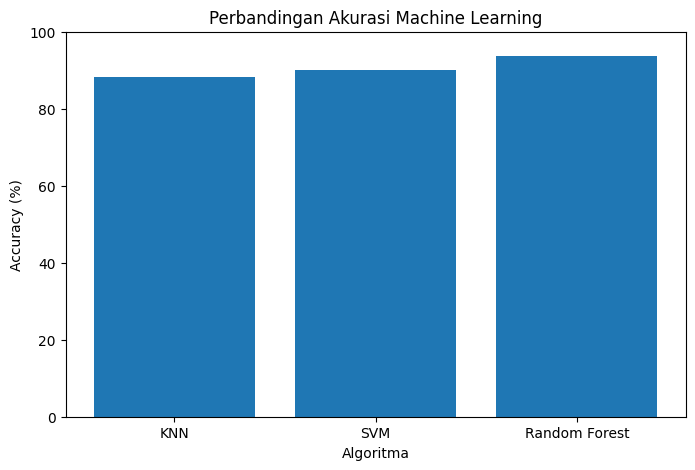

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    hasil_akurasi["Algoritma"],
    hasil_akurasi["Accuracy (%)"]
)

plt.title("Perbandingan Akurasi Machine Learning")
plt.xlabel("Algoritma")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.show()

Langkah 12. Classification Report

12.1 Memahami tujuan Classification Report

Classification Report merupakan metode evaluasi yang digunakan untuk mengetahui performa model klasifikasi berdasarkan nilai Precision, Recall, F1-Score, dan Support. Dalam penelitian ini, Classification Report digunakan untuk mengevaluasi kemampuan algoritma KNN, SVM, dan Random Forest dalam mengklasifikasikan kualitas pisang ke dalam empat kategori, yaitu Grade A, Grade B, Grade C, dan Grade D.

12.2 Menghitung Classification Report

In [ ]:
from sklearn.metrics import classification_report

print("===== CLASSIFICATION REPORT KNN =====")
print(classification_report(y_test, y_pred_knn))

print("===== CLASSIFICATION REPORT SVM =====")
print(classification_report(y_test, y_pred_svm))

print("===== CLASSIFICATION REPORT RANDOM FOREST =====")
print(classification_report(y_test, y_pred_rf))

===== CLASSIFICATION REPORT KNN =====
              precision    recall  f1-score   support

     Grade A       0.90      0.89      0.89       500
     Grade B       0.83      0.84      0.83       500
     Grade C       0.90      0.95      0.92       500
     Grade D       0.91      0.86      0.88       500

    accuracy                           0.88      2000
   macro avg       0.88      0.88      0.88      2000
weighted avg       0.88      0.88      0.88      2000

===== CLASSIFICATION REPORT SVM =====
              precision    recall  f1-score   support

     Grade A       0.94      0.91      0.93       500
     Grade B       0.84      0.90      0.87       500
     Grade C       0.93      0.94      0.94       500
     Grade D       0.90      0.85      0.88       500

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000

===== CLASSIFICATION REPORT RANDOM FOREST =====
      

Langkah 13. Confusion Matrix

13.1 Memahami tujuan Confusion Matrix

Confusion Matrix merupakan metode evaluasi yang digunakan untuk mengetahui perbandingan antara hasil klasifikasi yang diprediksi oleh model dengan label sebenarnya. Melalui Confusion Matrix, kita dapat melihat jumlah prediksi yang benar maupun salah pada setiap kategori grade pisang sehingga dapat diketahui kelas yang paling mudah dan paling sulit dikenali oleh model.

13.2 Membuat Confusion Matrix

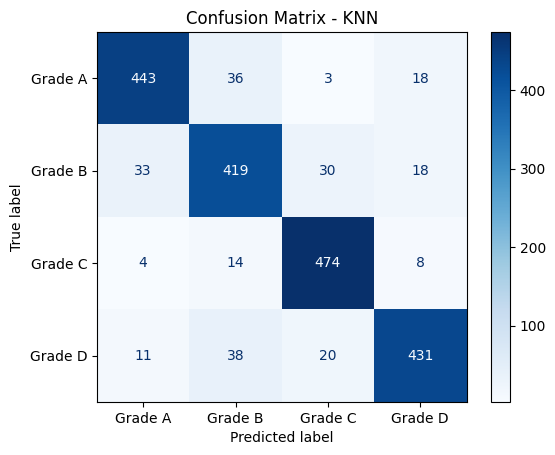

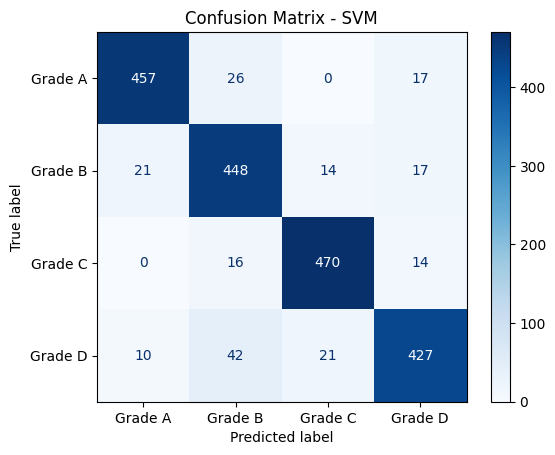

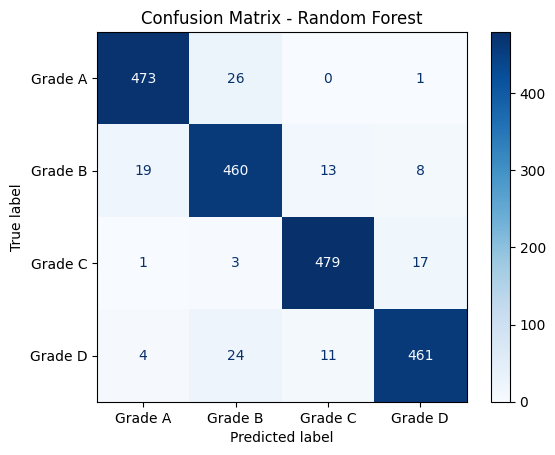

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predictions = {
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf
}

for name, prediction in predictions.items():

    cm = confusion_matrix(
        y_test,
        prediction,
        labels=grades
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=grades
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

13.3 Grafik Prediksi Benar dan Salah per Grade

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Menggabungkan hasil prediksi ketiga model
predictions = {
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf
}

# Menghitung prediksi benar dan salah per grade
hasil_grade = []

for model_name, prediction in predictions.items():

    for grade in grades:

        # Mengambil data aktual berdasarkan grade
        mask = np.array(y_test) == grade

        # Mengambil prediksi untuk grade tersebut
        pred_grade = np.array(prediction)[mask]

        # Menghitung benar dan salah
        benar = np.sum(pred_grade == grade)
        salah = np.sum(pred_grade != grade)

        hasil_grade.append({
            "Algoritma": model_name,
            "Grade": grade,
            "Prediksi Benar": benar,
            "Prediksi Salah": salah,
            "Jumlah Data": len(pred_grade),
            "Akurasi (%)": (
                benar / len(pred_grade) * 100
                if len(pred_grade) > 0 else 0
            )
        })

df_hasil_grade = pd.DataFrame(hasil_grade)

display(df_hasil_grade)


,Algoritma,Grade,Prediksi Benar,Prediksi Salah,Jumlah Data,Akurasi (%)
0,KNN,Grade A,443,57,500,88.6
1,KNN,Grade B,419,81,500,83.8
2,KNN,Grade C,474,26,500,94.8
3,KNN,Grade D,431,69,500,86.2
4,SVM,Grade A,457,43,500,91.4
5,SVM,Grade B,448,52,500,89.6
6,SVM,Grade C,470,30,500,94.0
7,SVM,Grade D,427,73,500,85.4
8,Random Forest,Grade A,473,27,500,94.6
9,Random Forest,Grade B,460,40,500,92.0


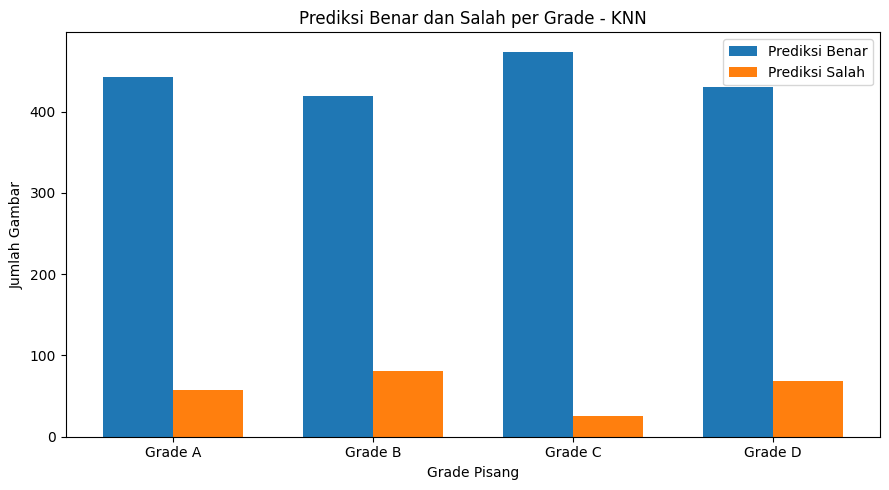

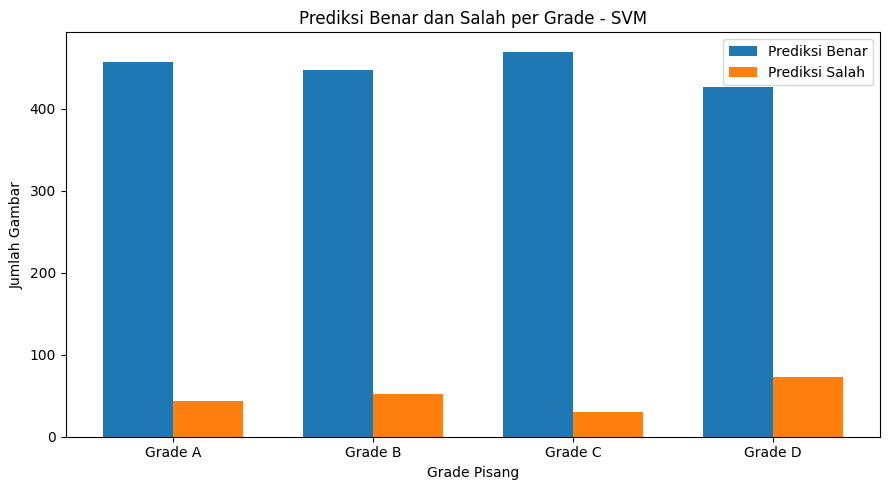

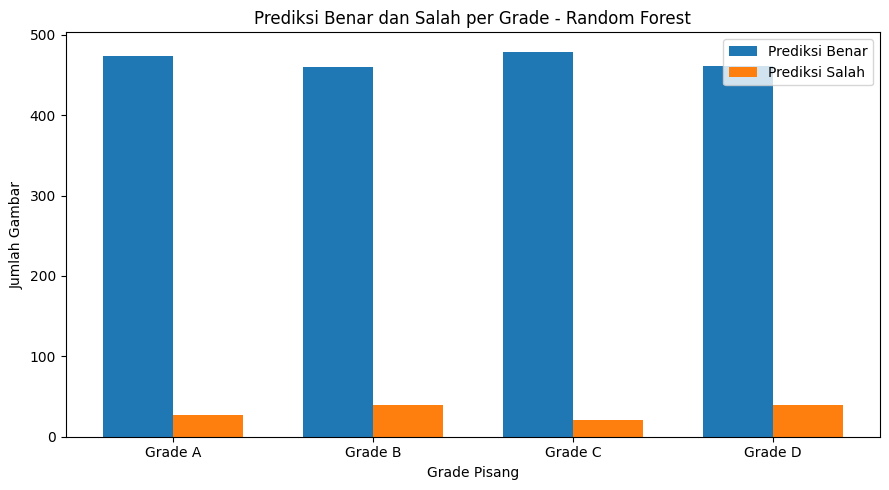

In [ ]:
for model_name in predictions.keys():

    data = df_hasil_grade[
        df_hasil_grade["Algoritma"] == model_name
    ]

    x = np.arange(len(data))
    width = 0.35

    plt.figure(figsize=(9, 5))

    plt.bar(
        x - width/2,
        data["Prediksi Benar"],
        width,
        label="Prediksi Benar"
    )

    plt.bar(
        x + width/2,
        data["Prediksi Salah"],
        width,
        label="Prediksi Salah"
    )

    plt.xticks(x, data["Grade"])

    plt.title(f"Prediksi Benar dan Salah per Grade - {model_name}")
    plt.xlabel("Grade Pisang")
    plt.ylabel("Jumlah Gambar")
    plt.legend()

    plt.tight_layout()
    plt.show()

Langkah 14. Eksperimen kombinasi fitur

14.1 Memahami tujuan eksperimen kombinasi fitur

Eksperimen kombinasi fitur merupakan proses pengujian beberapa kelompok fitur citra untuk mengetahui pengaruhnya terhadap performa klasifikasi. Dalam penelitian ini, fitur yang digunakan terdiri dari fitur warna (Color Features), fitur bentuk (Shape Features), dan fitur tekstur (Texture Features). Setiap kelompok fitur akan diuji secara terpisah maupun dikombinasikan untuk mengetahui kombinasi fitur yang mampu menghasilkan performa klasifikasi terbaik dalam membedakan Grade A, B, C, dan D.

14.2 Menentukan skenario eksperimen

Pada tahap ini, dilakukan penentuan skenario eksperimen berdasarkan kombinasi fitur citra yang akan digunakan dalam proses klasifikasi. Eksperimen dibagi menjadi empat skenario, yaitu penggunaan fitur warna (Color Features) saja, kombinasi fitur warna dan bentuk (Color + Shape), kombinasi fitur warna dan tekstur (Color + Texture), serta penggabungan seluruh fitur yang terdiri dari warna, bentuk, dan tekstur (Color + Shape + Texture). Setiap skenario akan diuji menggunakan tiga algoritma Classical Machine Learning, yaitu K-Nearest Neighbors (KNN), Support Vector Machine (SVM), dan Random Forest. Pengujian ini bertujuan untuk mengetahui pengaruh setiap kombinasi fitur terhadap performa klasifikasi serta menentukan kombinasi fitur dan algoritma terbaik dalam mengklasifikasikan kualitas pisang ke dalam Grade A, B, C, dan D.

14.3 Menyiapkan kelompok fitur

In [ ]:
# Membuat skenario kombinasi fitur

experiments = {
    "E1 - Color": color_features,

    "E2 - Color + Shape":
        color_features + shape_features,

    "E3 - Color + Texture":
        color_features + texture_features,

    "E4 - Color + Shape + Texture":
        color_features + shape_features + texture_features
}

# Memeriksa jumlah fitur setiap eksperimen
for name, features in experiments.items():

    print(name, ":", len(features), "fitur")

E1 - Color : 12 fitur
E2 - Color + Shape : 18 fitur
E3 - Color + Texture : 16 fitur
E4 - Color + Shape + Texture : 22 fitur


14.4 Melatih model berdasarkan kombinasi fitur

In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

hasil_eksperimen = []

for experiment_name, selected_features in experiments.items():

    # Mengambil fitur training dan testing
    Xtr = df_train[selected_features]
    Xte = df_test[selected_features]

    # Normalisasi untuk KNN dan SVM
    scaler_exp = StandardScaler()

    Xtr_scaled = scaler_exp.fit_transform(Xtr)
    Xte_scaled = scaler_exp.transform(Xte)

    # Model KNN
    model_knn = KNeighborsClassifier(n_neighbors=5)
    model_knn.fit(Xtr_scaled, y_train)
    pred_knn = model_knn.predict(Xte_scaled)

    # Model SVM
    model_svm = SVC(kernel="rbf", C=1, gamma="scale")
    model_svm.fit(Xtr_scaled, y_train)
    pred_svm = model_svm.predict(Xte_scaled)

    # Model Random Forest
    model_rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    model_rf.fit(Xtr, y_train)
    pred_rf = model_rf.predict(Xte)

    # Menghitung evaluasi
    model_results = {
        "KNN": pred_knn,
        "SVM": pred_svm,
        "Random Forest": pred_rf
    }

    for model_name, prediction in model_results.items():

        accuracy = accuracy_score(y_test, prediction)
        f1 = f1_score(
            y_test,
            prediction,
            average="macro",
            zero_division=0
        )

        hasil_eksperimen.append({
            "Eksperimen": experiment_name,
            "Algoritma": model_name,
            "Accuracy (%)": accuracy * 100,
            "Macro F1-Score (%)": f1 * 100
        })

# Membuat tabel hasil eksperimen
df_eksperimen = pd.DataFrame(hasil_eksperimen)

display(df_eksperimen)


,Eksperimen,Algoritma,Accuracy (%),Macro F1-Score (%)
0,E1 - Color,KNN,90.45,90.433535
1,E1 - Color,SVM,86.60,86.469789
2,E1 - Color,Random Forest,93.95,93.959824
3,E2 - Color + Shape,KNN,88.50,88.476763
4,E2 - Color + Shape,SVM,89.05,89.050762
5,E2 - Color + Shape,Random Forest,93.70,93.716879
6,E3 - Color + Texture,KNN,89.45,89.460580
7,E3 - Color + Texture,SVM,89.30,89.293707
8,E3 - Color + Texture,Random Forest,93.40,93.413801
9,E4 - Color + Shape + Texture,KNN,88.35,88.335017


14.5 Membandingkan hasil eksperimen

In [ ]:
hasil_urut = df_eksperimen.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(hasil_urut)

,Eksperimen,Algoritma,Accuracy (%),Macro F1-Score (%)
2,E1 - Color,Random Forest,93.95,93.959824
5,E2 - Color + Shape,Random Forest,93.70,93.716879
11,E4 - Color + Shape + Texture,Random Forest,93.65,93.657962
8,E3 - Color + Texture,Random Forest,93.40,93.413801
0,E1 - Color,KNN,90.45,90.433535
10,E4 - Color + Shape + Texture,SVM,90.10,90.113477
6,E3 - Color + Texture,KNN,89.45,89.460580
7,E3 - Color + Texture,SVM,89.30,89.293707
4,E2 - Color + Shape,SVM,89.05,89.050762
3,E2 - Color + Shape,KNN,88.50,88.476763


14.6 Membuat grafik perbandingan kombinasi fitur

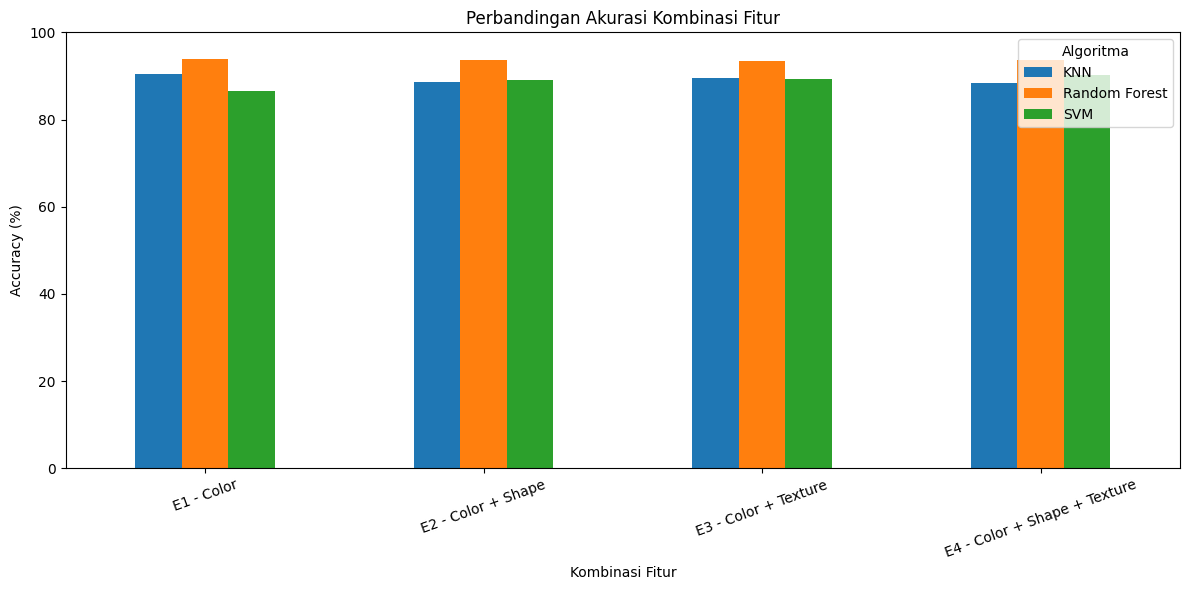

In [ ]:
import matplotlib.pyplot as plt

pivot_akurasi = df_eksperimen.pivot(
    index="Eksperimen",
    columns="Algoritma",
    values="Accuracy (%)"
)

pivot_akurasi.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Perbandingan Akurasi Kombinasi Fitur")
plt.xlabel("Kombinasi Fitur")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.legend(title="Algoritma")
plt.tight_layout()
plt.show()

14.7 Membuat ringkasan hasil eksperimen

In [ ]:
# Mengurutkan hasil berdasarkan Accuracy
hasil_terbaik = df_eksperimen.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print("=== 5 HASIL EKSPERIMEN TERBAIK ===")
display(hasil_terbaik.head(5))

# Mencari hasil terbaik secara keseluruhan
best_result = hasil_terbaik.iloc[0]

print("\n=== MODEL TERBAIK ===")
print("Eksperimen:", best_result["Eksperimen"])
print("Algoritma:", best_result["Algoritma"])
print("Accuracy:", best_result["Accuracy (%)"])
print("Macro F1-Score:", best_result["Macro F1-Score (%)"])

=== 5 HASIL EKSPERIMEN TERBAIK ===


,Eksperimen,Algoritma,Accuracy (%),Macro F1-Score (%)
2,E1 - Color,Random Forest,93.95,93.959824
5,E2 - Color + Shape,Random Forest,93.70,93.716879
11,E4 - Color + Shape + Texture,Random Forest,93.65,93.657962
8,E3 - Color + Texture,Random Forest,93.40,93.413801
0,E1 - Color,KNN,90.45,90.433535



=== MODEL TERBAIK ===
Eksperimen: E1 - Color
Algoritma: Random Forest
Accuracy: 93.95
Macro F1-Score: 93.95982383126736
